# CPU cost on the kiosks

**Final project · Intelligent museum guide** · issue #9

The kiosks run on **modest CPUs**, so the recommendation to the director needs real costs, not only accuracy. For
each candidate model we measure, for **one painting at a time** (batch size 1, as on a kiosk):

1. the **CPU time to classify it**, on **one thread** (`torch.set_num_threads(1)`, and one thread for the NumPy
   and scikit-learn computations too) to emulate a modest CPU;
2. the **number of parameters**;
3. the **size of the saved model**, the file a kiosk has to store and load.

**What is timed**: everything from the 128 × 128 image in [0, 1], the output of our data pipeline, to the
predicted style: resizing, normalisation, colour histogram or ResNet features, and the model itself. Decoding the
photo and resizing it to 128 pixels are the same for every model, so they are left out. Each model is first run
on 20 paintings (warm-up: the first calls allocate memory and fill the caches), then on each of the **225 test
paintings**, one at a time: we keep the **median** time, which ignores the few calls slowed down by other programs,
and the 90th percentile.

**Real paintings, trained models.** The benchmark runs the models a kiosk would hold: the trained weights
`mlp.pt` and `resnet.pt`, the logistic regressions refitted on the training images with the settings chosen in the
baseline and resnet notebooks, and the normalisation statistics of the training images. The test accuracy is
measured here, on the same one-painting-at-a-time path that is timed, and compared with the accuracy the other
notebooks measured by batches: the two must agree, otherwise the kiosk code is not the code we evaluated. It needs
the data (`make_wikiart_subset.py`) and the weights: run the `mlp` and `resnet` notebooks first.

**How this notebook is organised**

- From `src/`: `load_splits` (the shared split), `MLP`, `ResNetClassifier` and `count_parameters` (models),
  `IMAGENET_MEAN` and `IMAGENET_STD` (normalisation of the ResNet), `classification_metrics`, `RESULTS_DIR`.
- Defined here:
  - `time_per_image(predict_one, images)`: warm-up, then median and 90th percentile of the time to classify one
    image, and the predictions;
  - `saved_size_mb(*parts)`: size of the saved model, with `torch.save` for a network and `pickle` for
    scikit-learn;
  - `resize` and `train_statistics(size)`: the resizing and the "train" normalisation of `src/data.py`;
  - `colour_histogram`: the same function as in the baseline notebook;
  - one `predict_*` function per model, for one image.
- `rows` collects one line per model; the last cells save it in `results/benchmark.csv` and plot
  `results/benchmark.png`.

In [1]:
import csv
import io
import json
import pickle
import platform
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

sys.path.append("..")
from src.data import IMAGENET_MEAN, IMAGENET_STD, load_splits
from src.models import MLP, ResNetClassifier, count_parameters
from src.train import RESULTS_DIR, classification_metrics

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(1)       # PyTorch computes on one CPU core, as on a modest kiosk
threadpool_limits(1)           # the same for NumPy and scikit-learn (their BLAS library)
N_WARMUP = 20
print(f"{platform.platform()} | PyTorch {torch.__version__}, {torch.get_num_threads()} thread")

baseline = json.loads((RESULTS_DIR / "baseline.json").read_text())
mlp_results = json.loads((RESULTS_DIR / "mlp.json").read_text())
resnet_results = json.loads((RESULTS_DIR / "resnet.json").read_text())
for weights in ["mlp.pt", "resnet.pt"]:
    if not (RESULTS_DIR / weights).exists():
        raise FileNotFoundError(f"results/{weights} is missing: run the {weights[:-3]} notebook first")
rows = []                      # one line per model, saved in results/benchmark.csv

macOS-27.0.1-arm64-arm-64bit | PyTorch 2.14.1, 1 thread


In [2]:
# the shared split, pixels kept in [0, 1] at 128 x 128: what the data pipeline gives to every model
splits, classes = load_splits("none", size=128, verbose=False)
X_train, y_train = splits["train"][0], splits["train"][1].numpy()
images, y_test = splits["test"][0], splits["test"][1].numpy()
print(f"{len(images)} test paintings, {len(X_train)} training paintings, {images.shape[-1]} px")


def resize(x, size):
    """A (N, 3, 128, 128) batch resized to (N, 3, size, size), as in src/data.py."""
    if size == x.shape[-1]:
        return x
    return F.interpolate(x, size=size, mode="bilinear", antialias=True, align_corners=False)


def train_statistics(size):
    """Mean and std per channel of the training images at this size: the "train" normalisation of src/data.py."""
    X = resize(X_train, size)
    return X.mean(dim=(0, 2, 3), keepdim=True), X.std(dim=(0, 2, 3), keepdim=True)


def time_per_image(predict_one, images=images):
    """Median and 90th percentile, in milliseconds, of the time to classify ONE image on one thread,
    and the predicted class of each image."""
    times, predictions = [], []
    with torch.inference_mode():           # no autograd graph: what a kiosk would run
        for x in images[:N_WARMUP]:
            predict_one(x)                 # warm-up, not timed
        for x in images:
            start = time.perf_counter()
            prediction = predict_one(x)
            times.append(time.perf_counter() - start)
            predictions.append(int(prediction[0]))
    return 1000 * float(np.median(times)), 1000 * float(np.percentile(times, 90)), predictions


def saved_size_mb(*parts):
    """Size in MB of the saved model: torch.save for a state_dict, pickle for a scikit-learn model."""
    total = 0
    for part in parts:
        buffer = io.BytesIO()
        if isinstance(part, dict):
            torch.save(part, buffer)
        else:
            pickle.dump(part, buffer)
        total += buffer.getbuffer().nbytes
    return total / 1e6


def add_row(name, predict_one, n_params, size_mb, input_px, expected, train_time_s, train_device, images=images):
    """Time the model on the test paintings and, when it has an expected result, measure its accuracy."""
    ms, ms_p90, predictions = time_per_image(predict_one, images)
    metrics = classification_metrics(y_test, predictions) if expected else {}
    rows.append({"model": name, "input_px": input_px, "n_params": n_params, "size_mb": size_mb,
                 "ms_per_image": ms, "ms_p90": ms_p90,
                 "accuracy": metrics.get("accuracy"), "macro_f1": metrics.get("macro_f1"),
                 "train_time_s": train_time_s, "train_device": train_device})
    print(f"{name:48s} {ms:6.3f} ms/image (p90 {ms_p90:7.3f}) | {n_params:>10,d} params | {size_mb:7.3f} MB")
    if expected:
        print(f"{'':48s} test accuracy {metrics['accuracy']:.3f} one painting at a time, "
              f"{expected['accuracy']:.3f} in results/")

225 test paintings, 1050 training paintings, 128 px


## 1. Classical baselines

The two logistic regressions of the baseline notebook, refitted on the training images with the image size, the
number of bins and the regularisation `C` chosen there. For the pixels, the image is shrunk to 16 × 16 and
normalised with the statistics of the training images; for the histograms, the 128 × 128 image is turned into
`3 × bins` fractions, then standardised. The majority class is left out: it does not look at the image. The
baselines were trained on the CPU.

In [3]:
cfg = baseline["logreg_pixels"]
size = cfg["image_size"]
PIXEL_MEAN, PIXEL_STD = train_statistics(size)
X_pixels = ((resize(X_train, size) - PIXEL_MEAN) / PIXEL_STD).reshape(len(X_train), -1).numpy()
pixel_model = LogisticRegression(C=cfg["C"], max_iter=2000).fit(X_pixels, y_train)


def predict_pixels(x):
    x = (resize(x[None], size) - PIXEL_MEAN) / PIXEL_STD
    return pixel_model.predict(x.reshape(1, -1).numpy())


add_row(f"Logistic regression, pixels ({size} px)", predict_pixels,
        pixel_model.coef_.size + pixel_model.intercept_.size, saved_size_mb(pixel_model), size,
        cfg, cfg["train_time_s"], "cpu")

Logistic regression, pixels (16 px)               0.073 ms/image (p90   0.083) |      3,845 params |   0.016 MB
                                                 test accuracy 0.369 one painting at a time, 0.369 in results/


In [4]:
def colour_histogram(img, bins):
    """Histogram of each channel of one (3, H, W) image in [0, 1], as fractions of the pixels: (3 * bins,)."""
    idx = (img * bins).long().clamp(0, bins - 1)          # bin of every pixel value
    counts = [torch.bincount(idx[c].flatten(), minlength=bins) for c in range(3)]
    return torch.cat(counts).float() / idx[0].numel()   # fractions: independent of the image size


cfg = baseline["logreg_histograms"]
bins = cfg["bins"]
H_train = torch.stack([colour_histogram(img, bins) for img in X_train]).numpy()
hist_model = make_pipeline(StandardScaler(), LogisticRegression(C=cfg["C"], max_iter=5000)).fit(H_train, y_train)


def predict_histogram(x):
    return hist_model.predict(colour_histogram(x, bins)[None].numpy())


add_row(f"Logistic regression, colour histograms ({bins} bins)", predict_histogram,
        hist_model[-1].coef_.size + hist_model[-1].intercept_.size, saved_size_mb(hist_model), 128,
        cfg, cfg["train_time_s"], "cpu")

Logistic regression, colour histograms (8 bins)   0.175 ms/image (p90   0.188) |        125 params |   0.002 MB
                                                 test accuracy 0.396 one painting at a time, 0.396 in results/


## 2. MLP

The final MLP of `results/mlp.json` with its trained weights `mlp.pt`: 32 × 32 images normalised with the
statistics of the training images, 3 hidden layers of 512 units. In `eval()` mode, dropout is switched off and
costs nothing. The MLP was trained on the CPU.

In [5]:
cfg = mlp_results["config"]
mlp = MLP(3 * cfg["size"] ** 2, width=cfg["width"], depth=cfg["depth"],
          activation=getattr(nn, cfg["activation"]), dropout=cfg["dropout"])
mlp.load_state_dict(torch.load(RESULTS_DIR / "mlp.pt", weights_only=True))
mlp.eval()
MLP_MEAN, MLP_STD = train_statistics(cfg["size"])


def predict_mlp(x):
    x = (resize(x[None], cfg["size"]) - MLP_MEAN) / MLP_STD
    return mlp(x).argmax(dim=1)


add_row(f"MLP, {cfg['depth']} × {cfg['width']} ({cfg['size']} px)", predict_mlp, count_parameters(mlp),
        saved_size_mb(mlp.state_dict()), cfg["size"], mlp_results, mlp_results["train_time_s"], "cpu")

MLP, 3 × 512 (32 px)                              0.082 ms/image (p90   0.088) |  2,101,253 params |   8.408 MB
                                                 test accuracy 0.440 one painting at a time, 0.440 in results/


## 3. ResNet-18

Two deployment options share the same architecture:

- the **fine-tuned ResNet-18**, the whole network with its 5-class head, with the weights `resnet.pt`;
- the **frozen ResNet-18 features + logistic regression**: the ImageNet backbone, *not* fine-tuned, without its
  head gives 512 features, then a standardised logistic regression refitted on the features of the training
  images. The kiosk stores the backbone weights and the small scikit-learn model.

Both were trained on the laptop GPU (MPS); here the features are computed on the CPU, which can change the last
digits of a feature and, rarely, a prediction. We also time the fine-tuned network on **224 × 224** images, the
ImageNet resolution: it was not trained at this size, so it has no accuracy, but its cost tells what this lever
would mean on a kiosk.

In [6]:
resnet = ResNetClassifier()
resnet.load_state_dict(torch.load(RESULTS_DIR / "resnet.pt", weights_only=True))   # the fine-tuned weights
resnet.eval()                              # ResNetClassifier always stays in eval mode anyway


def predict_resnet(x):
    x = (x[None] - IMAGENET_MEAN) / IMAGENET_STD
    return resnet(x).argmax(dim=1)


cfg = resnet_results["finetuned"]
add_row("ResNet-18 fine-tuned (128 px)", predict_resnet, count_parameters(resnet),
        saved_size_mb(resnet.state_dict()), cfg["size"], cfg, cfg["train_time_s"], cfg["device"])

ResNet-18 fine-tuned (128 px)                     4.611 ms/image (p90   4.719) | 11,179,077 params |  44.795 MB
                                                 test accuracy 0.804 one painting at a time, 0.804 in results/


In [7]:
cfg = resnet_results["logreg_features"]
backbone = ResNetClassifier().eval()      # ImageNet weights (downloaded once into the PyTorch cache), not fine-tuned
with torch.inference_mode():              # features of the training images, by batches: a few seconds on one core
    F_train = torch.cat([backbone.features((xb - IMAGENET_MEAN) / IMAGENET_STD)
                         for xb in X_train.split(128)]).numpy()
features_model = make_pipeline(StandardScaler(), LogisticRegression(C=cfg["C"], max_iter=3000)).fit(F_train, y_train)
backbone_weights = {k: v for k, v in backbone.state_dict().items() if not k.startswith("resnet.fc")}   # no head


def predict_features(x):
    x = (x[None] - IMAGENET_MEAN) / IMAGENET_STD
    return features_model.predict(backbone.features(x).numpy())


add_row("ResNet-18 features + logistic regression", predict_features,
        count_parameters(backbone) - count_parameters(backbone.resnet.fc)
        + features_model[-1].coef_.size + features_model[-1].intercept_.size,
        saved_size_mb(backbone_weights, features_model), 128, cfg, cfg["train_time_s"],
        resnet_results["finetuned"]["device"])

ResNet-18 features + logistic regression          4.760 ms/image (p90   4.870) | 11,179,077 params |  44.805 MB
                                                 test accuracy 0.769 one painting at a time, 0.769 in results/


In [8]:
# the same network on the test paintings enlarged to 224 x 224: cost only, it was not trained at this size
images_224 = resize(images, 224)
add_row("ResNet-18 at 224 px (cost only)", predict_resnet, count_parameters(resnet),
        saved_size_mb(resnet.state_dict()), 224, {}, None, None, images=images_224)
print(f"224 / 128 px: {rows[-1]['ms_per_image'] / rows[-3]['ms_per_image']:.1f} times the time per painting "
      f"for (224 / 128)² = {(224 / 128) ** 2:.1f} times the pixels")

ResNet-18 at 224 px (cost only)                   9.736 ms/image (p90   9.896) | 11,179,077 params |  44.795 MB
224 / 128 px: 2.1 times the time per painting for (224 / 128)² = 3.1 times the pixels


## 4. Comparison

In [9]:
with open(RESULTS_DIR / "benchmark.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    for row in rows:
        # 4 significant digits are enough; an empty cell when there is no value (the 224 px row)
        writer.writerow({k: "" if v is None else f"{v:.4g}" if isinstance(v, float) else v for k, v in row.items()})

print(f"{'model':48s} {'ms/image':>9s} {'MB':>7s} {'params':>11s} {'accuracy':>8s}")
for r in rows:
    accuracy = f"{r['accuracy']:8.3f}" if r["accuracy"] is not None else f"{'-':>8s}"
    print(f"{r['model']:48s} {r['ms_per_image']:9.3f} {r['size_mb']:7.3f} {r['n_params']:11,d} {accuracy}")

model                                             ms/image      MB      params accuracy
Logistic regression, pixels (16 px)                  0.073   0.016       3,845    0.369
Logistic regression, colour histograms (8 bins)      0.175   0.002         125    0.396
MLP, 3 × 512 (32 px)                                 0.082   8.408   2,101,253    0.440
ResNet-18 fine-tuned (128 px)                        4.611  44.795  11,179,077    0.804
ResNet-18 features + logistic regression             4.760  44.805  11,179,077    0.769
ResNet-18 at 224 px (cost only)                      9.736  44.795  11,179,077        -


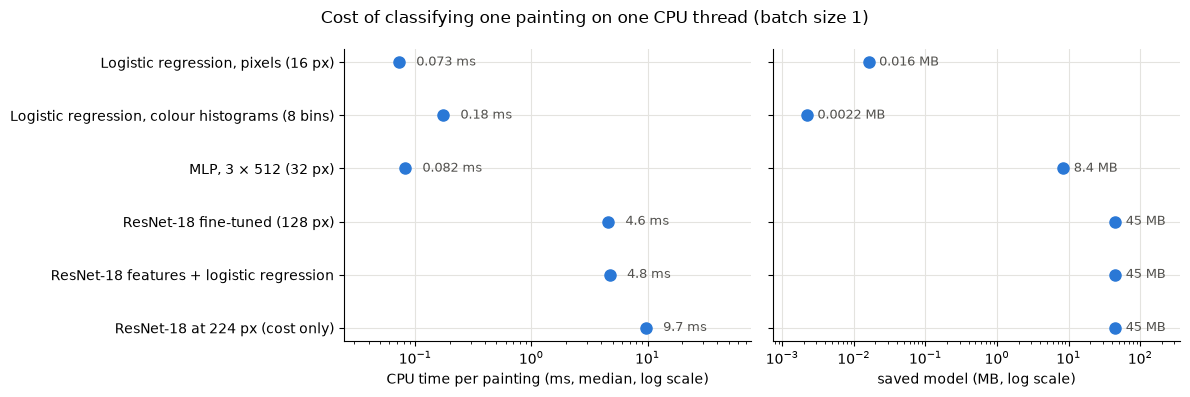

In [10]:
names = [r["model"] for r in rows][::-1]          # cheapest model at the top
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, key, label, fmt in [(axes[0], "ms_per_image", "CPU time per painting (ms, median, log scale)", "{:.2g} ms"),
                            (axes[1], "size_mb", "saved model (MB, log scale)", "{:.2g} MB")]:
    values = [r[key] for r in rows][::-1]
    # dots, not bars: on a log scale the length of a bar depends on where the axis starts
    ax.plot(values, names, "o", color="#2a78d6", markersize=8)
    ax.set_xscale("log")                           # the models span four orders of magnitude
    ax.set_xlim(min(values) / 3, max(values) * 8)  # room for the labels next to the dots
    for i, v in enumerate(values):
        ax.text(v * 1.4, i, fmt.format(v), va="center", fontsize=9, color="#52514e")
    ax.set_xlabel(label)
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.suptitle("Cost of classifying one painting on one CPU thread (batch size 1)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "benchmark.png", dpi=120)
plt.show()

**What we see.** Two runs of the notebook give the same times within a few percent.

- **The kiosk path gives the accuracies of the notebooks.** Classified one at a time through the timed
  functions, the 225 test paintings give exactly the accuracy and the macro-F1 that the other notebooks
  measured by batches, for the five models; computing the ResNet features on the CPU instead of the laptop
  GPU changes neither.
- **The classical models and the MLP cost 0.1 to 0.2 ms per painting** on one thread. The MLP has 2.1 million
  weights, but it does only one multiplication per weight, about 2 million in all, which a CPU core does in a
  fraction of a millisecond. Its 8.4 MB file is the only visible difference with the logistic regressions.
- **The ResNet-18 costs about 4.6 ms per painting**, some 55 times more than the MLP, because its convolutions
  apply each filter at every position of the image. That is still about 200 paintings per second on one core.
- **The two ResNet options cost the same** (4.6 and 4.8 ms, 45 MB): the backbone does almost all the work and holds
  99.98 % of the weights. The logistic regression on top adds about 0.1 ms and 10 kB.
- **224 pixels would double the time** (9.7 ms, 2.1 times), less than the 3.1 times more pixels: part of the work,
  such as calling each layer and the last layers on small feature maps, does not grow with the image.
- **Training costs** (from `results/`): under 0.3 s on the CPU for the logistic regressions, 1.5 s for the MLP, 15 s
  on the laptop GPU for the fine-tuned ResNet, and 0.3 s for the features + logistic regression, feature extraction
  included.

## What we take from it

- **On a kiosk, the CPU cost is not an argument against the ResNet.** 5 ms or 0.1 ms per painting are both
  invisible to a visitor, and a 45 MB file is loaded once when the kiosk starts. What separates the models is
  accuracy: 0.80 against 0.44 at best without deep features.
- **There is a large margin.** One core of this laptop (Apple M5 Pro) is faster than a modest kiosk CPU, but the
  ResNet would stay under 0.1 s per painting on a CPU 20 times slower.
- **The choice between the two ResNet options will not be made on cost**, which is the same, but on accuracy (within
  the noise of each other) and on maintenance: the logistic regression retrains in seconds on a CPU when the
  collection changes. That is the recommendation of issue #10.

**Limits.** These are times on one thread of an ARM laptop, not on the kiosk itself: before deployment, this notebook
should be run once on the real hardware, where only the absolute times should change, not the ranking. The time to
decode the photo, the memory used and the start-up time of the kiosk were not measured.